# Credit Risk Analysis: Who Defaults, and Can We Predict It?

**Dataset:** [Give Me Some Credit](https://www.kaggle.com/competitions/GiveMeSomeCredit) (Kaggle) – 150,000 borrowers  
**Target:** `SeriousDlqin2yrs` → did the borrower become **90+ days past due within 2 years**? (renamed `default` below)

### Business problem
A lender wants to know **which customers are likely to default** and **what characteristics go with repayment problems**, so it can approve, price and monitor loans more wisely.

### Questions this notebook answers
| # | Question | Section |
|---|----------|---------|
| 1 | What percentage of borrowers default? | 3 |
| 2 | Which customer characteristics are associated with default? | 4 |
| 3 | Does loan amount (credit exposure) affect default rates? | 5 |
| 4 | How does income relate to repayment? | 6 |
| 5 | Which customer segments have the highest risk? | 7 |
| 6 | Can we predict whether a borrower will default? | 8 |
| 7 | What factors matter most to the prediction? | 9 |
| – | Export results for the Tableau dashboard | 10 |

> **How to read this notebook:** every code cell is short and commented, and each section ends with a plain-English takeaway.
> Run top-to-bottom (`Kernel → Restart & Run All`). It takes about 2–3 minutes.

## 1. Setup
Import libraries, set a few constants (file paths, a fixed random seed so results are repeatable), and choose a consistent colour palette for charts.

In [37]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 30

# ---- constants -------------------------------------------------------------
RANDOM_STATE = 42                      # makes every random step repeatable
def find_data_dir():
    """Locate cs-training.csv wherever the notebook is run from.
    Looks in the project layout first (../data/raw), then the current folder and its neighbours.
    If only GiveMeSomeCredit.zip is found, it is unzipped automatically."""
    here = Path.cwd()
    folders = [here / "../data/raw", here / "data/raw", here, here / "..", here / "data", here / "../data"]
    for folder in folders:
        if (folder / "cs-training.csv").exists():
            return folder.resolve()
    for folder in folders:                                    # fall back to the original Kaggle zip
        zip_file = folder / "GiveMeSomeCredit.zip"
        if zip_file.exists():
            import zipfile
            target = folder.resolve() / "GiveMeSomeCredit_unzipped"
            zipfile.ZipFile(zip_file).extractall(target)
            print("Unzipped", zip_file.name, "->", target)
            return target
    raise FileNotFoundError(
        "Could not find cs-training.csv. Put cs-training.csv (and cs-test.csv) in a 'data/raw' folder "
        "next to this notebook's folder, or in the same folder as the notebook. Current folder: " + str(here))

DATA_DIR = find_data_dir()
print("Data folder:", DATA_DIR)

# Output folders: use the project layout if it exists, otherwise one simple 'outputs' folder
if (Path.cwd() / "../data/raw").exists():
    PROCESSED, FIG_DIR, TABLEAU_DIR = Path("../data/processed"), Path("../reports/figures"), Path("../tableau/data")
else:
    PROCESSED = FIG_DIR = TABLEAU_DIR = Path("outputs")
for folder in (PROCESSED, FIG_DIR, TABLEAU_DIR):
    folder.mkdir(parents=True, exist_ok=True)

BLUE, RED, GREY = "#2F5D8A", "#C0392B", "#8C8C8C"   # chart colours


def save_fig(name):
    """Save the current chart into reports/figures (used later in the Word report)."""
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

Data folder: C:\Users\hp\OneDrive\Documents\project\Loan Default & Credit Risk Prediction\credit-risk-project\data\raw


## 2. Load, audit and clean the data

### 2.1 Load and rename columns
The original column names are long, we are renaming them into short, readable names make the rest of the code much easier to follow.

In [2]:
COLUMN_NAMES = {
    "SeriousDlqin2yrs":                      "default",       # 1 = 90+ days late within 2 yrs
    "RevolvingUtilizationOfUnsecuredLines":  "utilization",   # card/credit-line balance ÷ credit limit
    "age":                                   "age",
    "NumberOfTime30-59DaysPastDueNotWorse":  "late_30_59",    # times 30-59 days late (last 2 yrs)
    "DebtRatio":                             "debt_ratio",    # monthly debt payments ÷ monthly income
    "MonthlyIncome":                         "income",
    "NumberOfOpenCreditLinesAndLoans":       "open_lines",    # open loans + credit lines
    "NumberOfTimes90DaysLate":               "late_90",       # times 90+ days late
    "NumberRealEstateLoansOrLines":          "real_estate",   # mortgages / home-equity lines
    "NumberOfTime60-89DaysPastDueNotWorse":  "late_60_89",    # times 60-89 days late (last 2 yrs)
    "NumberOfDependents":                    "dependents",
}

raw = pd.read_csv(DATA_DIR / "cs-training.csv", index_col=0).rename(columns=COLUMN_NAMES)
raw.index.name = "borrower_id"
print(f"{raw.shape[0]:,} borrowers, {raw.shape[1]} columns")
raw.head()

150,000 borrowers, 11 columns


,default,utilization,age,late_30_59,debt_ratio,income,open_lines,late_90,real_estate,late_60_89,dependents
borrower_id,,,,,,,,,,,
1,1,0.766,45,2,0.803,"9,120.000",13,0,6,0,2.000
2,0,0.957,40,0,0.122,"2,600.000",4,0,0,0,1.000
3,0,0.658,38,1,0.085,"3,042.000",2,1,0,0,0.000
4,0,0.234,30,0,0.036,"3,300.000",5,0,0,0,0.000
5,0,0.907,49,1,0.025,"63,588.000",7,0,1,0,0.000


### 2.2 Data-quality audit
Before analysing anything, look for problems. Real credit data is rarely clean.

In [3]:
audit = pd.DataFrame({
    "missing":     raw.isna().sum(),
    "missing_%":   raw.isna().mean() * 100,
    "min":         raw.min(),
    "median":      raw.median(),
    "99th_pctile": raw.quantile(0.99),
    "max":         raw.max(),
})
audit

,missing,missing_%,min,median,99th_pctile,max
default,0,0.000,0.000,0.000,1.000,1.000
utilization,0,0.000,0.000,0.154,1.093,"50,708.000"
age,0,0.000,0.000,52.000,87.000,109.000
late_30_59,0,0.000,0.000,0.000,4.000,98.000
debt_ratio,0,0.000,0.000,0.367,"4,979.040","329,664.000"
income,29731,19.821,0.000,"5,400.000","25,000.000","3,008,750.000"
open_lines,0,0.000,0.000,8.000,24.000,58.000
late_90,0,0.000,0.000,0.000,3.000,98.000
real_estate,0,0.000,0.000,1.000,4.000,54.000
late_60_89,0,0.000,0.000,0.000,2.000,98.000


In [4]:
late_cols = ["late_30_59", "late_60_89", "late_90"]

print("Issues found")
print("-" * 70)
print(f"1. Missing income:                       {raw['income'].isna().sum():>7,}  ({raw['income'].isna().mean():.1%})")
print(f"2. Missing dependents:                   {raw['dependents'].isna().sum():>7,}  ({raw['dependents'].isna().mean():.1%})")
print(f"3. Age below 18:                         {(raw['age'] < 18).sum():>7,}")
code_rows = (raw[late_cols] >= 96).any(axis=1)
print(f"4. Past-due counts of 96 or 98:          {code_rows.sum():>7,}  <- look like placeholder codes, not real counts")
print(f"5. Utilization above 200%:               {(raw['utilization'] > 2).sum():>7,}  (max = {raw['utilization'].max():,.0f}x!)")
bad_dr = raw["income"].isna() | (raw["debt_ratio"] > 5)
print(f"6. Debt ratio unreliable (no income or >5): {bad_dr.sum():>5,}  (max = {raw['debt_ratio'].max():,.0f})")

print()
print("Default rate of the odd '96/98' rows vs everyone else:")
print(f"   96/98 rows: {raw[code_rows]['default'].mean():.1%}    all others: {raw[~code_rows]['default'].mean():.1%}")

Issues found
----------------------------------------------------------------------
1. Missing income:                        29,731  (19.8%)
2. Missing dependents:                     3,924  (2.6%)
3. Age below 18:                               1
4. Past-due counts of 96 or 98:              269  <- look like placeholder codes, not real counts
5. Utilization above 200%:                   371  (max = 50,708x!)
6. Debt ratio unreliable (no income or >5): 32,083  (max = 329,664)

Default rate of the odd '96/98' rows vs everyone else:
   96/98 rows: 54.6%    all others: 6.6%


**What this tells us and how we handle each issue**

| Issue | Why it happens | Our treatment |
|---|---|---|
| Missing **income** (20%) | Not reported | Keep the row, add an `income_missing` flag, fill with the median *inside the model pipeline* (so the median is learned from training data only) |
| Missing **dependents** (2.6%) | Not reported | Same: flag + median |
| **Age 0** (1 row) | Data-entry error | Drop it |
| Past-due counts **96 / 98** | These look like placeholder codes. Those rows default at ~55%, far above average, so they carry information | Set the count to 0 and add a `delinq_code_flag` so the information is **kept, not hidden** |
| **Utilization** up to 50,708× | Entry errors; a few % over 100% is genuine (over-limit accounts) | Cap at 2.0 (200%) |
| **Debt ratio** in the thousands | When income is missing, the field holds a raw dollar amount, not a ratio | Treat as unreliable → blank it out, add `debt_ratio_unreliable` flag |
| Income outliers (up to 3 million/month) | Probably errors | Cap at 50,000 |


> **Principle:** where unsure, *flag and keep* rather than delete. Deleting 20% of rows because income is blank would bias the results.

### 2.3 Cleaning function
All rules in one place, so they are easy to review, test and reuse (we will reuse it on the Kaggle test file too).

In [ ]:
UTILIZATION_CAP = 2.0       # 200% of credit limit
INCOME_CAP      = 50_000    # monthly income
DEBT_RATIO_MAX  = 5         # above this the ratio is not credible


def clean_data(df):
    """Apply the cleaning rules from section 2.2. Returns a new DataFrame."""
    df = df.copy()

    # 1) Remove impossible ages
    df = df[df["age"] >= 18]

    # 2) 96/98 are placeholder codes -> flag them, then reset the counts to 0
    df["delinq_code_flag"] = (df[late_cols] >= 96).any(axis=1).astype(int)
    for col in late_cols:
        df.loc[df[col] >= 96, col] = 0

    # 3) Cap extreme utilization
    df["utilization"] = df["utilization"].clip(upper=UTILIZATION_CAP)

    # 4) Income: flag missing, cap outliers (missing values are filled later, in the model pipeline)
    df["income_missing"] = df["income"].isna().astype(int)
    df["income"] = df["income"].clip(upper=INCOME_CAP)

    # 5) Debt ratio is only trustworthy when income is known and the value is plausible

    unreliable = df["income"].isna() | (df["debt_ratio"] > DEBT_RATIO_MAX)
    df["debt_ratio_unreliable"] = unreliable.astype(int)
    df.loc[unreliable, "debt_ratio"] = np.nan

    # 6) Dependents: flag missing
    df["dependents_missing"] = df["dependents"].isna().astype(int)

    return df

df = clean_data(raw)
print(f"Rows before: {len(raw):,}   rows after: {len(df):,}   (dropped {len(raw) - len(df)})")
df.describe().T[["count", "mean", "min", "50%", "max"]]

Rows before: 150,000   rows after: 149,999   (dropped 1)


,count,mean,min,50%,max
default,"149,999.000",0.067,0.000,0.000,1.000
utilization,"149,999.000",0.324,0.000,0.154,2.000
age,"149,999.000",52.296,21.000,52.000,109.000
late_30_59,"149,999.000",0.245,0.000,0.000,13.000
debt_ratio,"117,916.000",0.361,0.000,0.290,5.000
income,"120,268.000","6,472.824",0.000,"5,400.000","50,000.000"
open_lines,"149,999.000",8.453,0.000,8.000,58.000
late_90,"149,999.000",0.090,0.000,0.000,17.000
real_estate,"149,999.000",1.018,0.000,1.000,54.000
late_60_89,"149,999.000",0.065,0.000,0.000,11.000


### 2.4 Create readable groups ("bands") for analysis
Raw numbers like 0.4173 are hard to interpret. Grouping into bands (age 26–35, utilization 30–50 %) lets us compare default rates side by side. 

Missing values get their own **"Unknown"** band so they stay visible.

In [6]:
def make_band(series, edges, labels, unknown_label="Unknown"):
    """Cut a numeric column into labelled bands; missing values become `unknown_label`."""
    banded = pd.cut(series, bins=edges, labels=labels, include_lowest=True)
    banded = banded.cat.add_categories(unknown_label).fillna(unknown_label)
    return banded


def add_bands(df):
    """Add human-readable band columns used for charts, segments and Tableau."""
    df = df.copy()
    df["age_band"] = make_band(df["age"], [17, 25, 35, 45, 55, 65, 120],
                               ["18-25", "26-35", "36-45", "46-55", "56-65", "65+"])
    df["income_band"] = make_band(df["income"], [-1, 2500, 4000, 5500, 7500, 10000, 50000],
                                  ["<2.5k", "2.5-4k", "4-5.5k", "5.5-7.5k", "7.5-10k", "10k+"])
    df["utilization_band"] = make_band(df["utilization"], [-0.01, 0.1, 0.3, 0.5, 0.75, 1.0, 2.0],
                                       ["0-10%", "10-30%", "30-50%", "50-75%", "75-100%", ">100%"])
    df["debt_ratio_band"] = make_band(df["debt_ratio"], [-0.01, 0.2, 0.4, 0.6, 1.0, 5.0],
                                      ["0-0.2", "0.2-0.4", "0.4-0.6", "0.6-1.0", "1.0-5.0"])
    df["open_lines_band"] = make_band(df["open_lines"], [-1, 2, 5, 8, 12, 100],
                                      ["0-2", "3-5", "6-8", "9-12", "13+"])
    df["dependents_band"] = make_band(df["dependents"], [-1, 0, 1, 2, 3, 100],
                                      ["0", "1", "2", "3", "4+"])

    # Payment history: the single most intuitive risk grouping
    df["past_due_history"] = np.select(
        [(df["late_90"] > 0) | (df["late_60_89"] > 0), df["late_30_59"] > 0],
        ["60+ days late", "30-59 days late only"],
        default="Never late",
    )
    return df


df = add_bands(df)
df[["age", "age_band", "income", "income_band", "utilization", "utilization_band", "past_due_history"]].head()

,age,age_band,income,income_band,utilization,utilization_band,past_due_history
borrower_id,,,,,,,
1,45,36-45,"9,120.000",7.5-10k,0.766,75-100%,30-59 days late only
2,40,36-45,"2,600.000",2.5-4k,0.957,75-100%,Never late
3,38,36-45,"3,042.000",2.5-4k,0.658,50-75%,60+ days late
4,30,26-35,"3,300.000",2.5-4k,0.234,10-30%,Never late
5,49,46-55,"50,000.000",10k+,0.907,75-100%,30-59 days late only


## 3. Q1 – What percentage of borrowers default?

Borrowers:         149,999
Defaulted:         10,026
Default rate:      6.68%   (about 1 in 15 borrowers)
Did not default:   139,973


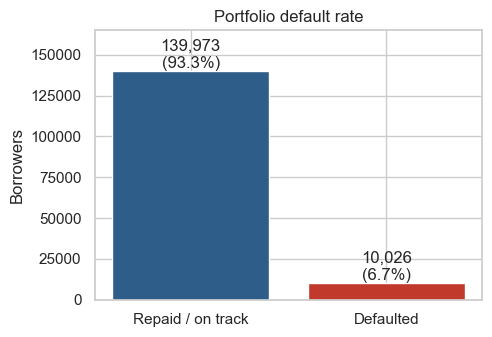

In [7]:
n_borrowers  = len(df)
n_defaults   = int(df["default"].sum())
default_rate = df["default"].mean()

print(f"Borrowers:         {n_borrowers:,}")
print(f"Defaulted:         {n_defaults:,}")
print(f"Default rate:      {default_rate:.2%}   (about 1 in {1 / default_rate:.0f} borrowers)")
print(f"Did not default:   {n_borrowers - n_defaults:,}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Repaid / on track", "Defaulted"], [n_borrowers - n_defaults, n_defaults], color=[BLUE, RED])
for i, v in enumerate([n_borrowers - n_defaults, n_defaults]):
    ax.text(i, v, f"{v:,}\n({v / n_borrowers:.1%})", ha="center", va="bottom")
ax.set_ylim(0, n_borrowers * 1.1)
ax.set_title("Portfolio default rate")
ax.set_ylabel("Borrowers")
save_fig("01_default_rate.png")

**Takeaway:** the data is **imbalanced**, about 93 % of borrowers are fine and only ~7 % default. 
This matters for modelling: a lazy model that says *"nobody defaults"* would be 93 % accurate yet completely useless. 
So we will judge models with **AUC, precision/recall and lift**, not plain accuracy.

## 4. Q2 – Which customer characteristics are associated with default?

We compare the default rate across groups. Two small helper functions keep every chart consistent.

In [8]:
def default_rate_table(data, group_col):
    """Borrowers, defaults and default rate (%) for each value of `group_col`."""
    table = (data.groupby(group_col, observed=True)["default"]
                 .agg(borrowers="size", defaults="sum", default_rate_pct="mean"))
    table["default_rate_pct"] *= 100
    return table


def plot_default_rate(table, title, xlabel, filename, ax=None):
    """Bar chart of default rate by group, with the portfolio average as a dashed line."""
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(7, 3.8))
    bars = ax.bar(table.index.astype(str), table["default_rate_pct"], color=BLUE)
    ax.axhline(default_rate * 100, color=RED, linestyle="--", linewidth=1, label=f"Portfolio average ({default_rate:.1%})")
    for bar, rate in zip(bars, table["default_rate_pct"]):
        ax.text(bar.get_x() + bar.get_width() / 2, rate, f"{rate:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Default rate (%)")
    ax.set_ylim(0, table["default_rate_pct"].max() * 1.3)      # headroom so the legend never covers a bar
    ax.legend(loc="upper right", fontsize=8)
    if standalone:
        save_fig(filename)

### 4.1 Age

,borrowers,defaults,default_rate_pct
age_band,,,
18-25,3027,338,11.166
26-35,18458,2053,11.123
36-45,29819,2628,8.813
46-55,36690,2786,7.593
56-65,33406,1531,4.583
65+,28599,690,2.413


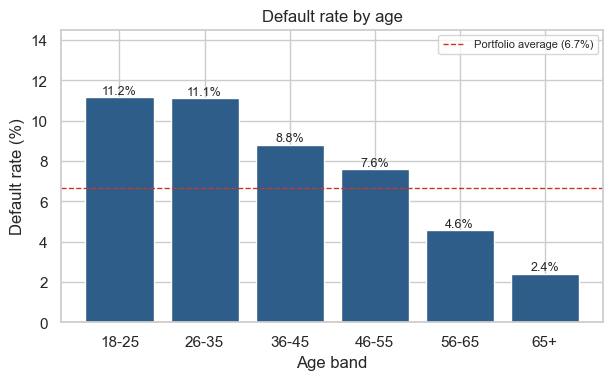

In [9]:
age_table = default_rate_table(df, "age_band")
plot_default_rate(age_table, "Default rate by age", "Age band", "02_default_by_age.png")
age_table

### 4.2 Payment history (the strongest signal)

,borrowers,defaults,default_rate_pct
past_due_history,,,
Never late,119906,3411,2.845
30-59 days late only,17213,2063,11.985
60+ days late,12880,4552,35.342


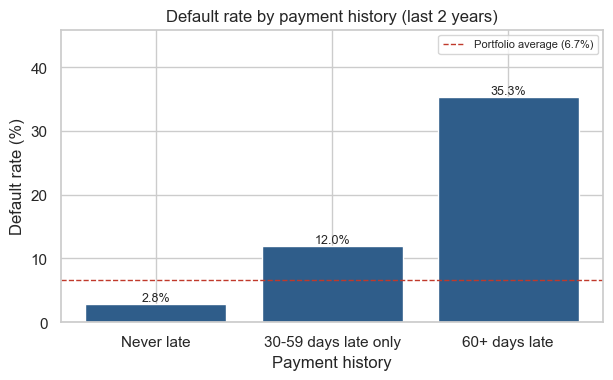

In [10]:
order = ["Never late", "30-59 days late only", "60+ days late"]
history_table = default_rate_table(df, "past_due_history").loc[order]
plot_default_rate(history_table, "Default rate by payment history (last 2 years)", "Payment history", "03_default_by_history.png")
history_table

Another view: how does the default rate climb with the *number* of times someone has been 90+ days late?

In [11]:
times_90 = df["late_90"].clip(upper=4).map({0: "0", 1: "1", 2: "2", 3: "3", 4: "4+"})
times_90_table = default_rate_table(df.assign(times_90_days_late=times_90), "times_90_days_late")
times_90_table

,borrowers,defaults,default_rate_pct
times_90_days_late,,,
0,141930,6701,4.721
1,5243,1765,33.664
2,1555,776,49.904
3,667,385,57.721
4+,604,399,66.060


### 4.3 Family situation

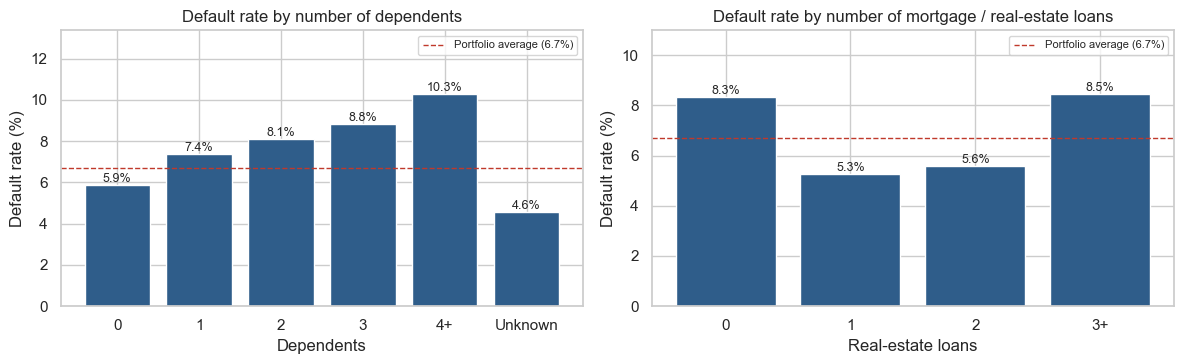

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_default_rate(default_rate_table(df, "dependents_band"), "Default rate by number of dependents", "Dependents", "", ax=axes[0])
real_estate_band = make_band(df["real_estate"], [-1, 0, 1, 2, 100], ["0", "1", "2", "3+"])
plot_default_rate(default_rate_table(df.assign(real_estate_band=real_estate_band), "real_estate_band"),
                  "Default rate by number of mortgage / real-estate loans", "Real-estate loans", "", ax=axes[1])
plt.tight_layout()
save_fig("04_default_by_family_realestate.png")

### 4.4 Which single variable lines up most strongly with default?

,spearman_corr
late_90,0.332
late_60_89,0.266
late_30_59,0.248
utilization,0.240
debt_ratio,0.060
dependents,0.046
real_estate,-0.034
open_lines,-0.039
income,-0.067
age,-0.117


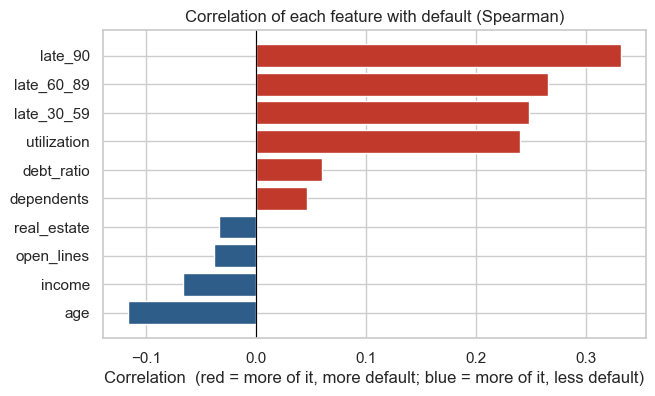

In [13]:
# Spearman correlation works for skewed data and counts (it only uses rank order)
numeric_features = ["utilization", "age", "late_30_59", "late_60_89", "late_90", "debt_ratio",
                    "income", "open_lines", "real_estate", "dependents"]
corr = df[numeric_features + ["default"]].corr(method="spearman")["default"].drop("default").sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(corr.index, corr.values, color=[RED if v > 0 else BLUE for v in corr.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlation of each feature with default (Spearman)")
ax.set_xlabel("Correlation  (red = more of it, more default; blue = more of it, less default)")
save_fig("05_correlation_with_default.png")
corr.sort_values(ascending=False).to_frame("spearman_corr")

**Takeaways (Q2)**
- **Payment history dominates.** Borrowers who have been late before default at many times the average rate; those 60+ days late are in a different league.
- **Revolving utilization** (how maxed-out the cards are) and **age** come next: younger and highly-utilised borrowers are riskier.
- **Dependents:** the default rate rises steadily with household size, from about 6 % with none to about 10 % with four or more, even though the overall correlation looks weak.
- **Real-estate loans** show a U-shape: borrowers with none or with 3+ default more (about 8 %) than those with one or two (about 5 %).
- These are *associations*, not proof of cause. For instance, young age may stand in for a short credit history.

## 5. Q3 – Does loan amount affect default rates?

> **Important data limitation:** this dataset has **no loan-amount column**. We cannot answer the question literally.  
> Instead we use the closest available measures of *how much credit a borrower is carrying*:
> **utilization** (balances ÷ limits), **debt ratio** (debt payments ÷ income), **number of open credit lines** and **number of real-estate loans**.

,borrowers,defaults,default_rate_pct
utilization_band,,,
0-10%,64404,1166,1.810
10-30%,28478,895,3.143
30-50%,15830,926,5.850
50-75%,13764,1394,10.128
75-100%,24202,4408,18.213
>100%,3321,1237,37.248


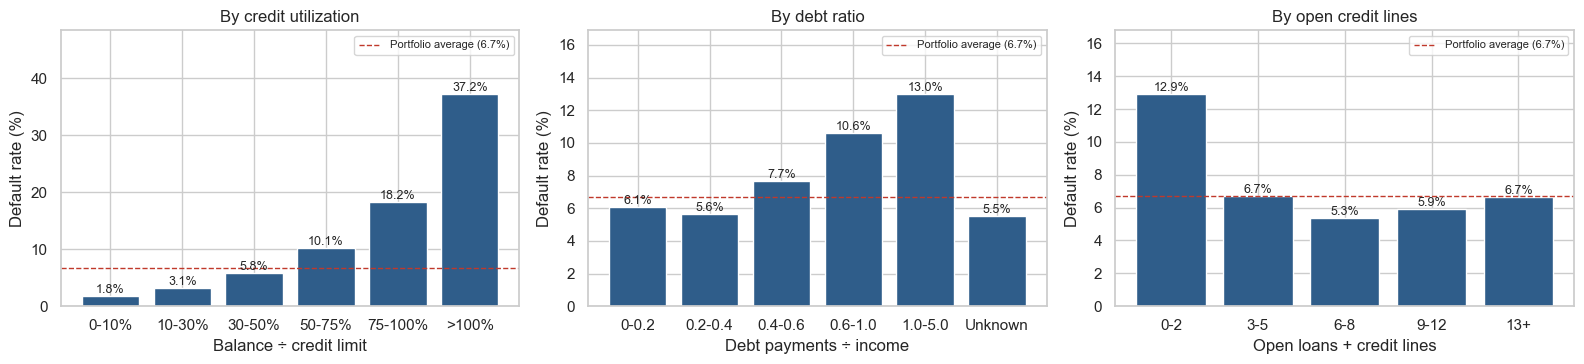

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
plot_default_rate(default_rate_table(df, "utilization_band"), "By credit utilization", "Balance ÷ credit limit", "", ax=axes[0])
plot_default_rate(default_rate_table(df, "debt_ratio_band"), "By debt ratio", "Debt payments ÷ income", "", ax=axes[1])
plot_default_rate(default_rate_table(df, "open_lines_band"), "By open credit lines", "Open loans + credit lines", "", ax=axes[2])
plt.tight_layout()
save_fig("06_default_by_exposure.png")
default_rate_table(df, "utilization_band")

In [15]:
default_rate_table(df, "debt_ratio_band")

,borrowers,defaults,default_rate_pct
debt_ratio_band,,,
0-0.2,40667,2476,6.088
0.2-0.4,38284,2156,5.632
0.4-0.6,21521,1656,7.695
0.6-1.0,12563,1336,10.634
1.0-5.0,4881,634,12.989
Unknown,32083,1768,5.511


**Takeaways (Q3)**
- **Utilization is a strong, steady driver:** default climbs sharply once borrowers use most of their available credit, and is highest for those *over* their limit.
- **Debt ratio** matters too, but the effect is more modest and only kicks in above ~0.6 (debt payments eating most of income).
- **Number of open lines:** borrowers with only 0-2 lines (a thin credit file) default at about 13 %, roughly double everyone else (5-7 %). Beyond 2 lines the rate is fairly flat.
- So "how much debt" matters, but **relative to limits and income**, not in absolute terms.

## 6. Q4 – How does income relate to repayment?

,borrowers,defaults,default_rate_pct
income_band,,,
<2.5k,18111,1572,8.680
2.5-4k,22287,2054,9.216
4-5.5k,21871,1669,7.631
5.5-7.5k,22246,1380,6.203
7.5-10k,17434,890,5.105
10k+,18319,792,4.323
Unknown,29731,1669,5.614


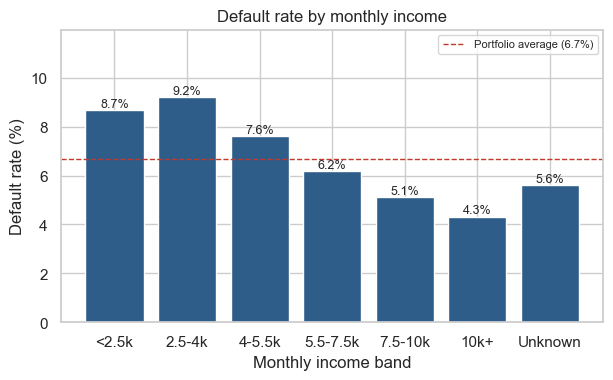

In [16]:
income_order = ["<2.5k", "2.5-4k", "4-5.5k", "5.5-7.5k", "7.5-10k", "10k+", "Unknown"]
income_table = default_rate_table(df, "income_band").loc[income_order]
plot_default_rate(income_table, "Default rate by monthly income", "Monthly income band", "07_default_by_income.png")
income_table

In [17]:
# Do defaulters earn less on average? (median is safer than mean because income is skewed)
known_income = df[df["income"].notna()]
print("Median monthly income")
print(known_income.groupby("default")["income"].median().rename({0: "Did not default", 1: "Defaulted"}).to_string())

# Rate of default across income quintiles (5 equal-sized groups)
quintile = pd.qcut(known_income["income"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
quintile_table = default_rate_table(known_income.assign(income_quintile=quintile), "income_quintile")
quintile_table

Median monthly income
default
Did not default   5,466.000
Defaulted         4,500.000


,borrowers,defaults,default_rate_pct
income_quintile,,,
Q1 (lowest),25084,2277,9.077
Q2,23024,1979,8.595
Q3,24056,1687,7.013
Q4,24084,1332,5.531
Q5 (highest),24020,1082,4.505


**Takeaways (Q4)**
- Default falls as income rises, **but the relationship is weaker than payment history or utilization**. Income alone is not a great predictor.
- Borrowers earning under 4k a month default most (about 9 %); the rate falls steadily to about 4 % for those earning 10k+. Median income is also lower for defaulters (about 4,500 vs 5,500).
- **Borrowers with unknown income** do *not* look riskier. Their default rate is actually slightly *below* average, so a missing value is a signal of its own, which is why we keep the `income_missing` flag.

## 7. Q5 – Which customer segments have the highest risk?

A **segment** combines several traits. We use three that are easy for a business to act on:
**payment history × credit utilization × age group** (3 × 3 × 3 = 27 segments).

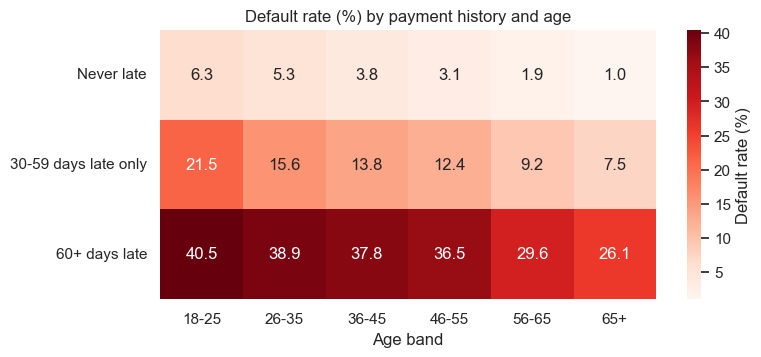

In [18]:
df["utilization_group"] = pd.cut(df["utilization"], [-0.01, 0.30, 0.75, 2.0],
                                 labels=["Low (<30%)", "Medium (30-75%)", "High (>75%)"]).astype(str)
df["age_group"] = pd.cut(df["age"], [17, 34, 54, 120],
                         labels=["Under 35", "35-54", "55+"]).astype(str)
df["segment"] = df["past_due_history"] + " | " + df["utilization_group"] + " util | " + df["age_group"]

# Heatmap: payment history (rows) × age band (columns) = average default rate
heat = df.pivot_table(index="past_due_history", columns="age_band", values="default", aggfunc="mean", observed=True) * 100
heat = heat.loc[order]
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Default rate (%)"}, ax=ax)
ax.set_title("Default rate (%) by payment history and age")
ax.set_xlabel("Age band"); ax.set_ylabel("")
save_fig("08_heatmap_history_age.png")

In [19]:
segments = (df.groupby("segment")["default"]
              .agg(borrowers="size", defaults="sum", default_rate_pct="mean")
              .assign(default_rate_pct=lambda t: t["default_rate_pct"] * 100))
segments["share_of_borrowers_%"] = segments["borrowers"] / n_borrowers * 100
segments["share_of_all_defaults_%"] = segments["defaults"] / n_defaults * 100
segments["risk_vs_average"] = segments["default_rate_pct"] / (default_rate * 100)    # "lift": 2.0 = twice the average
segments = segments[segments["borrowers"] >= 300].sort_values("default_rate_pct", ascending=False)  # ignore tiny groups

print("Top 8 riskiest segments (at least 300 borrowers):")
segments.head(8)

Top 8 riskiest segments (at least 300 borrowers):


,borrowers,defaults,default_rate_pct,share_of_borrowers_%,share_of_all_defaults_%,risk_vs_average
segment,,,,,,
60+ days late | High (>75%) util | 35-54,3818,1762,46.150,2.545,17.574,6.904
60+ days late | High (>75%) util | Under 35,1725,770,44.638,1.150,7.680,6.678
60+ days late | High (>75%) util | 55+,1507,617,40.942,1.005,6.154,6.125
60+ days late | Medium (30-75%) util | Under 35,437,143,32.723,0.291,1.426,4.896
60+ days late | Medium (30-75%) util | 35-54,1440,443,30.764,0.960,4.419,4.603
60+ days late | Medium (30-75%) util | 55+,848,219,25.825,0.565,2.184,3.864
30-59 days late only | High (>75%) util | Under 35,942,231,24.522,0.628,2.304,3.669
60+ days late | Low (<30%) util | Under 35,408,98,24.020,0.272,0.977,3.594


In [20]:
print("Safest 5 segments:")
segments.tail(5)

Safest 5 segments:


,borrowers,defaults,default_rate_pct,share_of_borrowers_%,share_of_all_defaults_%,risk_vs_average
segment,,,,,,
Never late | Medium (30-75%) util | 35-54,11234,549,4.887,7.489,5.476,0.731
Never late | Medium (30-75%) util | 55+,7615,244,3.204,5.077,2.434,0.479
Never late | Low (<30%) util | Under 35,7378,166,2.250,4.919,1.656,0.337
Never late | Low (<30%) util | 35-54,31153,476,1.528,20.769,4.748,0.229
Never late | Low (<30%) util | 55+,43484,355,0.816,28.990,3.541,0.122


The 5 riskiest segments hold 6.0% of borrowers but 37.3% of all defaults.


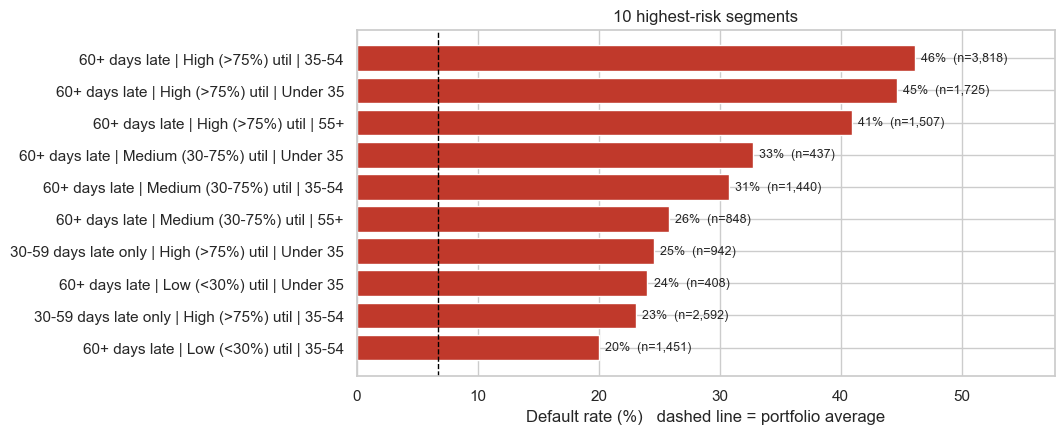

In [21]:
top = segments.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top["default_rate_pct"], color=RED)
ax.axvline(default_rate * 100, color="black", linestyle="--", linewidth=1)
for y, (rate, n) in enumerate(zip(top["default_rate_pct"], top["borrowers"])):
    ax.text(rate + 0.5, y, f"{rate:.0f}%  (n={n:,})", va="center", fontsize=9)
ax.set_xlim(0, top["default_rate_pct"].max() * 1.25)
ax.set_title("10 highest-risk segments")
ax.set_xlabel("Default rate (%)   dashed line = portfolio average")
save_fig("09_top_risk_segments.png")

top5_share = segments.head(5)["share_of_all_defaults_%"].sum()
top5_pop   = segments.head(5)["share_of_borrowers_%"].sum()
print(f"The 5 riskiest segments hold {top5_pop:.1f}% of borrowers but {top5_share:.1f}% of all defaults.")

**Takeaways (Q5)**
- The riskiest segments combine **a record of being 60+ days late** with **high credit utilization**: 41-46 % of these borrowers default, about 6-7 times the average, and this holds across all age groups.
- A small share of the portfolio produces a disproportionately large share of defaults (the top 5 segments are ~6 % of borrowers but ~37 % of defaults). That is where monitoring, collections effort and tighter approval rules pay off most.
- The safest group: **never late, low utilization, 55+**. These default well below 1 % and are the natural target for pre-approved offers.

## 8. Q6 – Can we predict whether a borrower will default?

Plan:
1. Build model inputs (features).
2. Hold back 20 % of borrowers as a **test set** that the models never see while learning.
3. Train three models of increasing complexity and compare them on the test set.

| Model | Why include it |
|---|---|
| **Logistic Regression** | Simple, fast, easy to explain to regulators and credit committees (the usual baseline in credit scoring) |
| **Random Forest** | Captures non-linear patterns and interactions automatically |
| **Gradient Boosting** (XGBoost if installed, otherwise scikit-learn's equivalent) | Usually the strongest on tabular data |

### 8.1 Features and train/test split

In [22]:
def add_model_features(df):
    """Create the extra columns the models use."""
    df = df.copy()
    df["total_past_due"] = df[late_cols].sum(axis=1)          # all late events together
    df["log_income"]     = np.log1p(df["income"])             # logs tame skewed values (helps Logistic Regression)
    df["log_debt_ratio"] = np.log1p(df["debt_ratio"])
    return df


FLAGS = ["income_missing", "dependents_missing", "debt_ratio_unreliable", "delinq_code_flag"]

# Tree models can use the raw numbers directly
TREE_FEATURES = ["utilization", "age", "late_30_59", "late_60_89", "late_90", "total_past_due",
                 "debt_ratio", "income", "open_lines", "real_estate", "dependents"] + FLAGS

# Logistic Regression works best with log-transformed versions of the skewed columns
LOGIT_FEATURES = [("log_debt_ratio" if f == "debt_ratio" else "log_income" if f == "income" else f)
                  for f in TREE_FEATURES]

model_df = add_model_features(df)
y = model_df["default"]

train_idx, test_idx = train_test_split(model_df.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
print(f"Train: {len(train_idx):,} borrowers ({y_train.mean():.2%} default)")
print(f"Test:  {len(test_idx):,} borrowers ({y_test.mean():.2%} default)   <- same default rate: split is stratified")

Train: 119,999 borrowers (6.68% default)
Test:  30,000 borrowers (6.68% default)   <- same default rate: split is stratified


### 8.2 Define the three models
Each model is a small *pipeline*: fill blanks with the median → (scale) → model. Putting the median-fill inside the pipeline means it is learned from **training data only**, which avoids leaking test information.

In [23]:
# Try XGBoost if it is installed; otherwise use scikit-learn's gradient boosting (same family of model)
try:
    from xgboost import XGBClassifier
    BOOSTER_NAME = "XGBoost"
    booster = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                            colsample_bytree=0.8, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1)
except ImportError:
    BOOSTER_NAME = "Gradient Boosting"
    booster = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=4,
                                             l2_regularization=1.0, random_state=RANDOM_STATE)
print("Boosting model used:", BOOSTER_NAME)

models = {
    "Logistic Regression": (
        Pipeline([("fill", SimpleImputer(strategy="median")),
                  ("scale", StandardScaler()),
                  ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
        LOGIT_FEATURES),
    "Random Forest": (
        Pipeline([("fill", SimpleImputer(strategy="median")),
                  ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features="sqrt",
                                                   class_weight="balanced_subsample", n_jobs=-1,
                                                   random_state=RANDOM_STATE))]),
        TREE_FEATURES),
    BOOSTER_NAME: (
        Pipeline([("model", booster)]),                 # boosting handles blanks on its own
        TREE_FEATURES),
}

Boosting model used: XGBoost


> `class_weight="balanced"` tells Logistic Regression and Random Forest to treat each rare default as if it counted more, so they do not simply ignore defaulters.

### 8.3 Train and evaluate

**Metrics, in plain English**
- **ROC AUC** – if we pick one defaulter and one non-defaulter at random, how often does the model give the defaulter the higher risk score? 0.5 = coin flip, 1.0 = perfect. Credit models typically reach 0.80–0.87.
- **PR AUC (average precision)** – like AUC but focused on the rare defaulters; more demanding when classes are imbalanced. The baseline is the default rate (~0.07).
- **KS statistic** – the largest gap between the cumulative score distribution of defaulters and non-defaulters. Banks commonly look for 0.40+.

In [24]:
results, test_scores = [], {}

for name, (pipeline, features) in models.items():
    pipeline.fit(model_df.loc[train_idx, features], y_train)
    scores = pipeline.predict_proba(model_df.loc[test_idx, features])[:, 1]      # probability of default
    test_scores[name] = scores

    fpr, tpr, _ = roc_curve(y_test, scores)
    results.append({"model": name,
                    "ROC AUC": roc_auc_score(y_test, scores),
                    "PR AUC": average_precision_score(y_test, scores),
                    "KS": (tpr - fpr).max()})

comparison = pd.DataFrame(results).set_index("model").sort_values("ROC AUC", ascending=False)
comparison

,ROC AUC,PR AUC,KS
model,,,
XGBoost,0.870,0.402,0.586
Random Forest,0.866,0.390,0.582
Logistic Regression,0.861,0.382,0.565


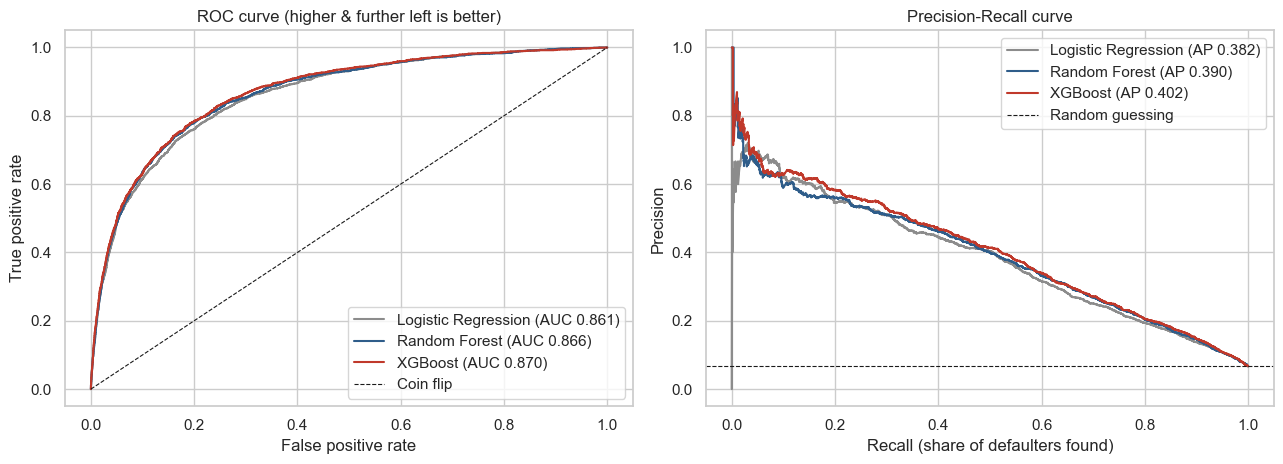

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
palette = {"Logistic Regression": GREY, "Random Forest": BLUE, BOOSTER_NAME: RED}

for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0].plot(fpr, tpr, color=palette[name], label=f"{name} (AUC {roc_auc_score(y_test, scores):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, scores)
    axes[1].plot(rec, prec, color=palette[name], label=f"{name} (AP {average_precision_score(y_test, scores):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Coin flip")
axes[0].set(title="ROC curve (higher & further left is better)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", linewidth=0.8, label="Random guessing")
axes[1].set(title="Precision-Recall curve", xlabel="Recall (share of defaulters found)", ylabel="Precision")
for ax in axes:
    ax.legend(loc="best")
plt.tight_layout()
save_fig("10_model_curves.png")

**Reading the results:** all three models rank borrowers well above chance. Logistic Regression is close behind the tree models, which says most of the signal is simple and roughly monotonic (more late payments → more risk).
The boosted model is slightly best, so we use it from here on for decisions, scoring and the dashboard. 
Logistic Regression remains valuable as the *explainable* benchmark.

**A robustness check:** a single train/test split can be lucky. We re-score *every* borrower with 5-fold cross-validation (each borrower is scored by a model that never saw them). 
These "out-of-fold" scores are also what we export to Tableau, so the dashboard never shows over-optimistic in-sample predictions.

In [26]:
final_model = models[BOOSTER_NAME][0]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_df["predicted_pd"] = cross_val_predict(final_model, model_df[TREE_FEATURES], y, cv=cv,
                                             method="predict_proba")[:, 1]    # PD = probability of default

oof_auc = roc_auc_score(y, model_df["predicted_pd"])
print(f"5-fold cross-validated ROC AUC for {BOOSTER_NAME}: {oof_auc:.4f}")
print(f"Hold-out test ROC AUC:                          {comparison.loc[BOOSTER_NAME, 'ROC AUC']:.4f}   (the two should agree closely)")

5-fold cross-validated ROC AUC for XGBoost: 0.8663
Hold-out test ROC AUC:                          0.8699   (the two should agree closely)


### 8.4 Are the predicted probabilities trustworthy? (Calibration)
If the model says "10 % chance of default" for a group of borrowers, about 10 % of them should actually default. 
This matters because we are about to use the probability directly to make approve/decline decisions.

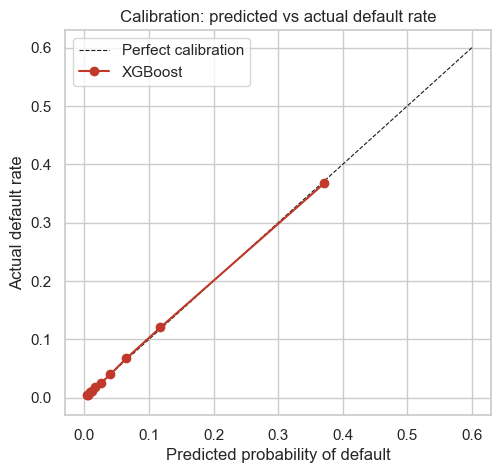

In [27]:
frac_actual, mean_predicted = calibration_curve(y, model_df["predicted_pd"], n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 0.6], [0, 0.6], "k--", linewidth=0.8, label="Perfect calibration")
ax.plot(mean_predicted, frac_actual, "o-", color=RED, label=BOOSTER_NAME)
ax.set(title="Calibration: predicted vs actual default rate", xlabel="Predicted probability of default",
       ylabel="Actual default rate")
ax.legend()
save_fig("11_calibration.png")

The points sit close to the diagonal, so the probabilities can be read at face value.

### 8.5 Turning probabilities into decisions
A model gives a *probability*; the lender needs a *decision* (approve / review / decline). The cut-off should reflect **what each mistake costs**:

| Mistake | What happens | Assumed cost |
|---|---|---|
| Approve someone who defaults (false negative) | Lose principal | **5 units** |
| Decline someone who would have repaid (false positive) | Lose profit on a good loan | **1 unit** |

> These cost numbers are an **illustrative assumption** – the real figures should come from the lender's finance team. Change `COST_DEFAULT` below and everything updates.

With calibrated probabilities, the cost-minimising cut-off has a simple formula: decline when  
`probability > cost_of_wrong_decline ÷ (cost_of_wrong_decline + cost_of_missed_default)` = 1 ÷ (1+5) ≈ **16.7 %**.

In [28]:
COST_DEFAULT = 5          # cost of approving a borrower who then defaults
COST_GOOD    = 1          # cost of declining a borrower who would have repaid
THRESHOLD    = COST_GOOD / (COST_GOOD + COST_DEFAULT)
print(f"Decision threshold: decline if predicted default probability > {THRESHOLD:.1%}")

decline = model_df["predicted_pd"] > THRESHOLD
tn, fp, fn, tp = confusion_matrix(y, decline).ravel()

pd.DataFrame({"Borrower repaid": [tn, fp], "Borrower defaulted": [fn, tp]},
             index=["Model says APPROVE", "Model says DECLINE"])

Decision threshold: decline if predicted default probability > 16.7%


,Borrower repaid,Borrower defaulted
Model says APPROVE,129795,4346
Model says DECLINE,10178,5680


In [29]:
cost_approve_all = n_defaults * COST_DEFAULT                     # approve everybody: every default hurts
cost_with_model  = fn * COST_DEFAULT + fp * COST_GOOD            # missed defaults + wrongly declined good borrowers

print(f"Defaulters caught (recall):        {tp / (tp + fn):.1%}")
print(f"Of those declined, truly default:   {tp / (tp + fp):.1%}   (precision; baseline is {default_rate:.1%})")
print(f"Share of all borrowers declined:    {decline.mean():.1%}")
print()
print(f"Total cost, approve everyone: {cost_approve_all:>10,.0f} units")
print(f"Total cost, use the model:    {cost_with_model:>10,.0f} units")
print(f"Cost reduction:               {1 - cost_with_model / cost_approve_all:>10.1%}")

Defaulters caught (recall):        56.7%
Of those declined, truly default:   35.8%   (precision; baseline is 6.7%)
Share of all borrowers declined:    10.6%

Total cost, approve everyone:     50,130 units
Total cost, use the model:        31,908 units
Cost reduction:                    36.3%


### 8.6 Lift: how well does the model concentrate risk?
Sort all borrowers from highest to lowest predicted risk and cut them into 10 equal groups (**deciles**). If the model is good, the top decile should contain far more defaulters than the bottom one.

,borrowers,defaults,default_rate_pct,lift_vs_average,cum_defaults_captured_%
risk_decile,,,,,
1,15000,5512,36.747,5.498,54.977
2,15000,1807,12.047,1.802,73.000
3,15000,1009,6.727,1.006,83.064
4,15000,600,4.000,0.598,89.048
5,15000,372,2.480,0.371,92.759
6,14999,273,1.820,0.272,95.482
7,15000,176,1.173,0.176,97.237
8,15000,136,0.907,0.136,98.594
9,15000,81,0.540,0.081,99.402


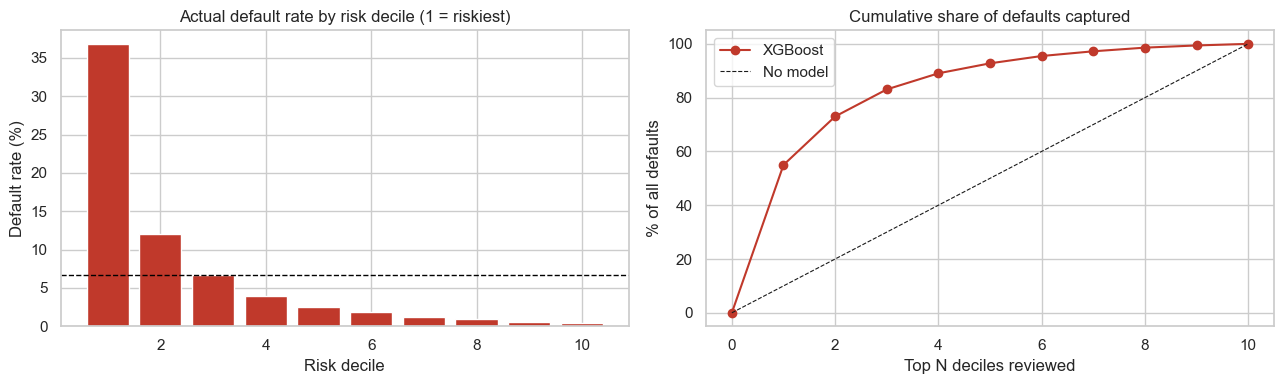

In [30]:
model_df["risk_decile"] = pd.qcut(model_df["predicted_pd"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)

lift = (model_df.groupby("risk_decile")["default"]
                .agg(borrowers="size", defaults="sum", default_rate_pct="mean"))
lift["default_rate_pct"] *= 100
lift["lift_vs_average"] = lift["default_rate_pct"] / (default_rate * 100)
lift["cum_defaults_captured_%"] = lift["defaults"].cumsum() / n_defaults * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(lift.index, lift["default_rate_pct"], color=RED)
axes[0].axhline(default_rate * 100, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Actual default rate by risk decile (1 = riskiest)", xlabel="Risk decile", ylabel="Default rate (%)")
axes[1].plot([0] + list(lift.index), [0] + list(lift["cum_defaults_captured_%"]), "o-", color=RED, label=BOOSTER_NAME)
axes[1].plot([0, 10], [0, 100], "k--", linewidth=0.8, label="No model")
axes[1].set(title="Cumulative share of defaults captured", xlabel="Top N deciles reviewed", ylabel="% of all defaults")
axes[1].legend()
plt.tight_layout()
save_fig("12_lift_deciles.png")
lift

In [31]:
print(f"Reviewing only the riskiest 10% of borrowers finds {lift.loc[1, 'cum_defaults_captured_%']:.0f}% of all defaults.")
print(f"Reviewing the riskiest 30% finds {lift.loc[3, 'cum_defaults_captured_%']:.0f}%.")

Reviewing only the riskiest 10% of borrowers finds 55% of all defaults.
Reviewing the riskiest 30% finds 83%.


**Takeaways (Q6)** – *Yes, default is predictable*, to a useful degree. The model ranks borrowers well, its probabilities are well calibrated, and it concentrates defaults heavily in the top deciles. 
It is not perfect: there is always some luck in who gets into trouble (job loss, illness), which no model of these ten variables can foresee.

## 9. Q7 – Which factors matter most to the prediction?

Two complementary views:

1. **Permutation importance** (works for any model): shuffle one feature at a time on the test data and see how much the AUC drops. A big drop = the model relied on that feature.
2. **Logistic Regression odds ratios** (easy to explain): for each 1-standard-deviation increase in a feature, by what factor do the *odds* of default change?

,feature,auc_drop,std
5,total_past_due,0.073,0.001
0,utilization,0.069,0.002
1,age,0.013,0.001
8,open_lines,0.006,0.000
6,debt_ratio,0.005,0.000
4,late_90,0.003,0.000
7,income,0.003,0.001
9,real_estate,0.002,0.000


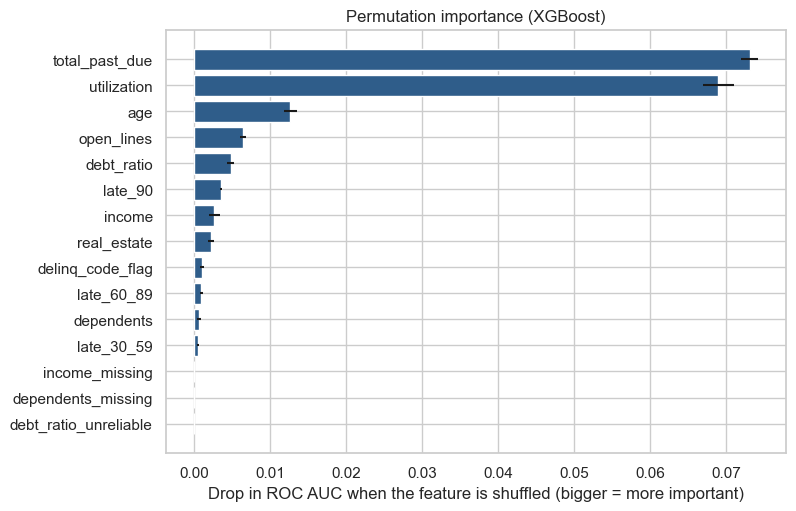

In [32]:
# Use a 25,000-row sample of the test set to keep this fast
sample_idx = np.random.RandomState(RANDOM_STATE).choice(test_idx, size=25_000, replace=False)

perm = permutation_importance(models[BOOSTER_NAME][0], model_df.loc[sample_idx, TREE_FEATURES], y.loc[sample_idx],
                              scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

importance = (pd.DataFrame({"feature": TREE_FEATURES, "auc_drop": perm.importances_mean, "std": perm.importances_std})
                .sort_values("auc_drop", ascending=True))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance["feature"], importance["auc_drop"], xerr=importance["std"], color=BLUE)
ax.set_title(f"Permutation importance ({BOOSTER_NAME})")
ax.set_xlabel("Drop in ROC AUC when the feature is shuffled (bigger = more important)")
save_fig("13_feature_importance.png")
importance.sort_values("auc_drop", ascending=False).head(8)

In [33]:
logit_pipeline = models["Logistic Regression"][0]
coefs = logit_pipeline.named_steps["model"].coef_[0]

odds = (pd.DataFrame({"feature": LOGIT_FEATURES, "odds_ratio_per_1sd": np.exp(coefs)})
          .sort_values("odds_ratio_per_1sd", ascending=False)
          .set_index("feature"))
odds

,odds_ratio_per_1sd
feature,
utilization,2.028
income_missing,1.489
late_90,1.429
total_past_due,1.403
late_60_89,1.240
late_30_59,1.203
open_lines,1.158
delinq_code_flag,1.118
log_debt_ratio,1.105


Read the odds ratio like this: `1.50` means each 1-SD increase multiplies the odds of default by 1.5 (+50 %); `0.70` means it cuts the odds by 30 %.

**Takeaways (Q7)**
- **Payment history** (counts of late payments) and **credit utilization** carry the most predictive weight.
- **Age** is next, with older borrowers safer (each extra standard deviation of age cuts the odds of default by about 25 %). (Using age in real credit decisions is restricted in many jurisdictions, so see the limitations section.)
- Debt ratio, income and the number of open lines add smaller increments.
- The **missing-value flags** (`income_missing`, `debt_ratio_unreliable`) overlap almost perfectly, so their odds ratios offset each other and should not be read separately. They simply tell the model that income was not reported.
- Permutation importance spreads credit across correlated features (the three late-payment counts and `total_past_due` share the same signal), so read the *group* of payment-history features as the top driver.

## 10. Export results for Tableau and GitHub

We save four small tables:

| File | Content | Used for |
|---|---|---|
| `borrower_risk_scores.csv` | One row per borrower: attributes, bands, segment, predicted probability, risk band | Main dashboard data source |
| `segment_summary.csv` | The 27 segments with default rates | Segment chart |
| `risk_decile_lift.csv` | Lift table | Model-performance page |
| `model_comparison.csv`, `feature_importance.csv` | Model results | Model-performance page |

**Risk bands** translate the probability into plain labels the business can use.

In [34]:
RISK_EDGES  = [0, 0.02, 0.05, 0.10, 0.20, 1.0]
RISK_LABELS = ["1 - Very Low (<2%)", "2 - Low (2-5%)", "3 - Medium (5-10%)", "4 - High (10-20%)", "5 - Very High (>20%)"]
model_df["risk_band"] = pd.cut(model_df["predicted_pd"], RISK_EDGES, labels=RISK_LABELS, include_lowest=True)
model_df["model_decision"] = np.where(model_df["predicted_pd"] > THRESHOLD, "Decline / review", "Approve")

# Do the risk bands behave sensibly? Actual default rate should climb steadily from band 1 to 5.
band_check = (model_df.groupby("risk_band", observed=True)["default"]
                       .agg(borrowers="size", actual_default_rate_pct="mean"))
band_check["actual_default_rate_pct"] *= 100
band_check

,borrowers,actual_default_rate_pct
risk_band,,
1 - Very Low (<2%),74065,0.955
2 - Low (2-5%),30694,3.206
3 - Medium (5-10%),20306,7.362
4 - High (10-20%),11550,14.095
5 - Very High (>20%),13384,38.942


In [35]:
export_cols = ["default", "age", "age_band", "income", "income_band", "utilization", "utilization_band",
               "debt_ratio", "debt_ratio_band", "open_lines", "open_lines_band", "real_estate", "dependents",
               "dependents_band", "late_30_59", "late_60_89", "late_90", "past_due_history",
               "segment", "predicted_pd", "risk_decile", "risk_band", "model_decision"]

(model_df[export_cols].rename_axis("borrower_id").reset_index()
    .round({"predicted_pd": 4, "utilization": 4, "debt_ratio": 4})
    .to_csv(TABLEAU_DIR / "borrower_risk_scores.csv", index=False))

segments.reset_index().round(2).to_csv(TABLEAU_DIR / "segment_summary.csv", index=False)
lift.reset_index().round(2).to_csv(TABLEAU_DIR / "risk_decile_lift.csv", index=False)
comparison.reset_index().round(4).to_csv(TABLEAU_DIR / "model_comparison.csv", index=False)
importance.sort_values("auc_drop", ascending=False).round(5).to_csv(TABLEAU_DIR / "feature_importance.csv", index=False)

print("Saved to", TABLEAU_DIR.resolve())
for f in sorted(TABLEAU_DIR.glob("*.csv")):
    print(f"  {f.name:<28} {f.stat().st_size / 1024:>9,.1f} KB")

Saved to C:\Users\hp\OneDrive\Documents\project\Loan Default & Credit Risk Prediction\credit-risk-project\tableau\data
  borrower_risk_scores.csv      24,264.4 KB
  feature_importance.csv             0.4 KB
  model_comparison.csv               0.1 KB
  risk_decile_lift.csv               0.4 KB
  segment_summary.csv                2.0 KB


### Bonus: score the Kaggle test file
The competition's `cs-test.csv` has no answers (that is the point of the contest), so we can only *generate* predictions in the required format (`Id, Probability`). 
We refit the final model on **all** labelled data and apply exactly the same cleaning steps.

In [36]:
test_raw = pd.read_csv(DATA_DIR / "cs-test.csv", index_col=0).rename(columns=COLUMN_NAMES)

# The cleaning function drops rows with age < 18; make sure no test row is lost (Kaggle needs every Id)
assert (test_raw["age"] >= 18).all(), "A test row would be dropped by clean_data()"

test_features = add_model_features(clean_data(test_raw))

final_model.fit(model_df[TREE_FEATURES], y)                      # refit on all labelled borrowers
submission = pd.DataFrame({"Id": test_features.index,
                           "Probability": final_model.predict_proba(test_features[TREE_FEATURES])[:, 1]})
submission.to_csv(PROCESSED / "kaggle_submission.csv", index=False)
print(f"{len(submission):,} test borrowers scored.  Average predicted default probability: {submission['Probability'].mean():.2%}")
submission.head()

101,503 test borrowers scored.  Average predicted default probability: 6.69%


,Id,Probability
0,1,0.066
1,2,0.043
2,3,0.017
3,4,0.075
4,5,0.099


## 11. Conclusions, recommendations and limitations

### Key findings
1. **About 6.7 % of borrowers (1 in 15) default** within two years, so the data is imbalanced and accuracy is the wrong yardstick.
2. **Payment history is the strongest signal.** Never-late borrowers default at 2.8 %; those 60+ days late at 35 %. Borrowers with four or more 90-day lates default about 66 % of the time.
3. **Credit utilization is the second driver:** from 1.8 % (under 10 % used) to 18 % (75-100 %) and 37 % for borrowers over their limit.
4. **Credit exposure (our stand-in for loan amount):** utilization and a debt ratio above 0.6 raise risk; a thin file (0-2 credit lines) doubles it. Absolute amounts cannot be tested because the data has no loan-amount field.
5. **Income has a moderate, steady effect** (about 9 % default below 4k per month vs 4 % above 10k). Missing income is *not* a red flag in this data.
6. **Younger borrowers are riskier:** 11 % default at 18-35 vs 2.4 % for 65+.
7. **Highest-risk segment:** 60+ days late with high utilization (41-46 % default). The top five segments are ~6 % of borrowers but ~37 % of defaults.
8. **Default is predictable.** The boosted model reaches **ROC AUC ~0.87** on held-out data (5-fold CV 0.866), KS 0.58, and well-calibrated probabilities. The simple Logistic Regression is only slightly behind at 0.86.
9. **Business value:** reviewing the riskiest 10 % of applicants finds 55 % of defaults and the riskiest 30 % finds 83 %. Under the assumed cost ratio (a missed default costs 5x a wrongly declined good loan), using the model cuts expected loss cost by about 36 % vs approving everyone.

### Recommendations
- **Underwriting:** auto-review or decline *Very High* risk-band applicants (>20 % predicted default; actual rate 39 %), and fast-track *Very Low* (<2 %; actual 0.95 %), which is almost half the portfolio.
- **Early-warning monitoring:** flag existing customers whose utilization crosses 75 % or who have a first 30-59 day late. These are leading indicators.
- **Pricing:** use risk bands for risk-based pricing rather than a single approve/decline cut-off.
- **Explainability:** keep Logistic Regression as the documented benchmark for regulators; use the boosted model for ranking.

### Limitations and next steps
- **No loan amount, interest rate, loan term or purpose** in the data; the exposure analysis uses proxies.
- **Cost ratio (5:1) is an assumption.** Replace it with real loss-given-default and margin figures.
- **Age as a feature:** it is predictive but is restricted or prohibited in credit decisions in many jurisdictions (e.g. ECOA in the US). A production model should be re-run without it and tested for fairness across groups.
- **Historic snapshot (about 2008-2011 era data):** economic conditions change, so models need monitoring and retraining.
- **Associations, not causes.**
- **XGBoost was not available** in the environment that produced these results, so scikit-learn's gradient boosting was used. Installing `xgboost` and re-running switches automatically; expect very similar numbers.
- **Next steps:** hyper-parameter tuning, SHAP explanations, a fairness audit, a scorecard (weight-of-evidence) version of the logistic model.